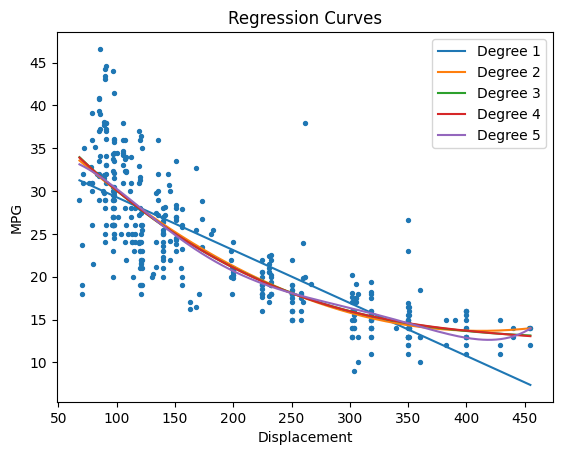

   Degree     MSE   RMSE     R2
0       1  18.103  4.255  0.663
1       2  15.107  3.887  0.719
2       3  14.944  3.866  0.722
3       4  14.961  3.868  0.722
4       5  15.231  3.903  0.717


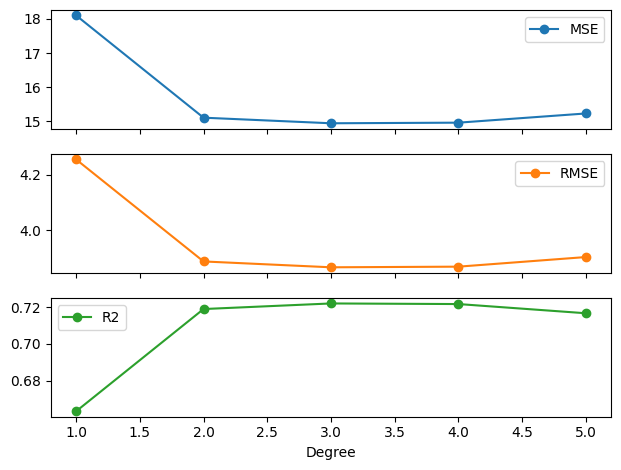

In [5]:

# ALGORITHM:
# 1. Import libraries and load Auto MPG dataset.
# 2. Remove missing values and select displacement and MPG.
# 3. Split data into training and testing sets.
# 4. Train Linear Regression and calculate predictions.
# 5. Train Polynomial Regression for degrees 2 to 5.
# 6. Calculate MSE, RMSE and R2 for all models.
# 7. Display and compare model performance.
# 8. Plot regression curves and performance graphs.
# 9. Stop.

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

d = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv")
d = d[['displacement','mpg']].dropna()
X, y = d[['displacement']], d.mpg
a, b, c, e = train_test_split(X, y, test_size=.2, random_state=42)
xx = pd.DataFrame({'displacement': np.linspace(X.min().iloc[0], X.max().iloc[0], 200)})
results = []

plt.scatter(X, y, s=8)
for n in range(1, 6):
    p = PolynomialFeatures(n) if n > 1 else None
    A = p.fit_transform(a) if p else a
    B = p.transform(b) if p else b
    model = LinearRegression().fit(A, c)
    pred = model.predict(B)
    mse = mean_squared_error(e, pred)
    results.append([n, mse, np.sqrt(mse), r2_score(e, pred)])
    plt.plot(xx, model.predict(p.transform(xx) if p else xx), label=f'Degree {n}')

plt.xlabel('Displacement'); plt.ylabel('MPG')
plt.title('Regression Curves'); plt.legend(); plt.show()

r = pd.DataFrame(results, columns=['Degree','MSE','RMSE','R2'])
print(r.round(3))
r.set_index('Degree')[['MSE','RMSE','R2']].plot(subplots=True, marker='o')
plt.tight_layout(); plt.show()
